In [1]:
import geopandas as gpd
import ee
import geemap
# ee.Authenticate()
# ee.Initialize()
import ipyleaflet

Enter verification code:  4/1AZEOvhXGUK-2KCf0-USsMWn-rIza0UAalFegx4LshK2WNfSOoZ9iI4hR6rU



Successfully saved authorization token.


In [5]:
#import data
#gdf= gpd.read_file('../../data/SSAr2_32628_GE01-QB02-WV02-WV03_PV_001_019_mosaic.gpkg')
# gdf= gpd.read_file('../../data/SSAr2_32637_GE01-QB02-WV02-WV03_PV_097_022_mosaic.gpkg') #saudi arabia?
# gdf= gpd.read_file('../../data/SSAr2_32636_GE01-QB02-WV02-WV03_PV_099_004_mosaic.gpkg') #egypt
# gdf= gpd.read_file('../../data/test_gpkg/SSAr2_32634_GE01-QB02-WV02-WV03_PV_095_036_mosaic.gpkg') #Libya
#gdf= gpd.read_file('../../data/SSAr2_32630_GE01-QB02-WV02-WV03-WV04_PV_091_010_mosaic.gpkg') #Mali
# gdf= gpd.read_file('../../data/SSAr2_32630_GE01-QB02-WV02-WV03-WV04_PV_058_002_mosaic.gpkg') #Mauritania
# gdf= gpd.read_file('../../data/SSAr2_32629_GE01-QB02-WV02-WV03_PV_078_009_mosaic.gpkg') #Mauritania
# gdf= gpd.read_file('../../data/SSAr2_32629_GE01-QB02-WV02-WV03_PV_046_041_mosaic.gpkg') #Mauritania
# gdf= gpd.read_file('../../data/SSAr2_32628_GE01-QB02-WV02-WV03_PV_079_031_mosaic.gpkg') #Mauritania
# gdf= gpd.read_file('../../data/SSAr2_32628_GE01-QB02-WV02-WV03_PV_041_008_mosaic.gpkg') #senegal
gdf= gpd.read_file('/Users/isabellopez/Desktop/SURGE/data/SSAr2_32628_GE01-QB02-WV02-WV03_PV_001_028_mosaic.gpkg')

In [2]:
#read every file
from os import listdir
from os.path import isfile, join

path='../../data/test_gpkg/'

files_all=[f for f in listdir(path) if isfile(join(path, f))]


In [21]:
from shapely.geometry import shape


In [3]:
# for feature in gdf['geometry']:
#     s=shape(feature['geometry'])
#     print(s.centroid)

cell_df=gdf(crs=crs)

NameError: name 'gdf' is not defined

In [4]:
gdf

NameError: name 'gdf' is not defined

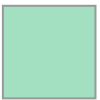

In [6]:
gdf.geometry[0]

In [7]:
#create empty map
Map = geemap.Map()

# search for boundary data from earth engine
country= ee.FeatureCollection('USDOS/LSIB_SIMPLE/2017')

# select specific country's boundary
roi=country.filter(ee.Filter.eq('country_na','Ethiopia'))

# add selected boundary to map
Map.addLayer(roi,{},'Ethiopia')

# center map on selected country
Map.centerObject(roi, 7)



In [8]:
# search for satellite data, and filter by date and region using selected country boundary
landsat = ee.ImageCollection("LANDSAT/LC08/C01/T1").filterDate("2016-01-01","2017-01-01").filterBounds(roi)

# combine image collection into single image
composite = ee.Algorithms.Landsat.simpleComposite(**{"collection": landsat,"asFloat": True})

# select which bands to display from the satellite imagery
rgbVis = {"bands": ["B4","B3","B2"], "min":0, "max":0.3}

# add bands to the map
Map.addLayer(composite.clip(roi),rgbVis, "Landsat RGB")

In [9]:
# convert DAAC tree data to ipyleaflet object
tree_data = ipyleaflet.GeoData(geo_dataframe=gdf, style={'color': 'black', 'fillColor': '#3366cc', 'opacity':0.07, 'weight':20, 'dashArray':'2', 'fillOpacity':0.6},
                   hover_style={'fillColor': 'red' , 'fillOpacity': 0.2}, name='DAAC trees' )
# add ipyleaflet object to the map
Map.add_layer(tree_data)


# add layer control to the map
#Map.add_control(ipyleaflet.LayersControl())
Map

Map(center=[8.624533627606269, 39.64042932753895], controls=(WidgetControl(options=['position', 'transparent_b…

In [20]:
gdf.explore()

In [27]:
gdf

,Area,Leaf_Mass,Wood_Mass,Root_Mass,geometry
0,5.75,1.273978,27.341690,10.957354,"POLYGON ((314730.000 2535322.000, 314729.000 2..."
1,3.75,0.863736,17.035810,7.742400,"POLYGON ((314595.500 2535208.500, 314595.500 2..."
2,5.25,1.172845,24.722780,10.176651,"POLYGON ((313702.000 2535061.000, 313701.500 2..."
3,5.00,1.121955,23.423134,9.781119,"POLYGON ((312338.500 2535043.500, 312337.500 2..."
4,5.00,1.121955,23.423134,9.781119,"POLYGON ((312239.500 2535041.500, 312238.000 2..."
...,...,...,...,...,...
6535,5.25,1.172845,24.722780,10.176651,"POLYGON ((315293.000 2519073.000, 315292.500 2..."
6536,5.50,1.223516,26.029057,10.568666,"POLYGON ((315805.000 2519071.500, 315804.000 2..."
6537,5.50,1.223516,26.029057,10.568666,"POLYGON ((319216.500 2519070.000, 319216.000 2..."
6538,5.00,1.121955,23.423134,9.781119,"POLYGON ((315740.000 2519067.500, 315739.500 2..."


In [29]:
## convert gdf to shapefile
import geopandas as gpd
import fiona


In [31]:
#gdf.to_file('gdf_SHP.shp', mode = "a")

In [44]:
# Path to the GeoPackage file
geopackage_path = '../../data/SSAr2_32630_GE01-QB02-WV02-WV03-WV04_PV_091_010_mosaic.gpkg'

# Read the GeoPackage file as a GeoDataFrame
gdf = gpd.read_file(geopackage_path)

# Path to the output Shapefile
shapefile_path = '/Users/isabellopez/Desktop/SURGE/notebooks/exploration/shapefiles/shap.shp'

# Convert the GeoDataFrame to a Shapefile
gdf.to_file(shapefile_path, driver='ESRI Shapefile')

In [54]:
# path to shapefile
#shap = 'notebooks/exploration/shapefiles/shap.shp'
shap = gpd.read_file(shapefile_path)
geo
ee_fc = geemap.shp_to_ee(shap)

,Area,Leaf_Mass,Wood_Mass,Root_Mass,geometry
0,5.75,1.273978,27.341690,10.957354,"POLYGON ((314730.000 2535322.000, 314732.000 2..."
1,3.75,0.863736,17.035810,7.742400,"POLYGON ((314595.500 2535208.500, 314597.500 2..."
2,5.25,1.172845,24.722780,10.176651,"POLYGON ((313702.000 2535061.000, 313704.000 2..."
3,5.00,1.121955,23.423134,9.781119,"POLYGON ((312338.500 2535043.500, 312340.000 2..."
4,5.00,1.121955,23.423134,9.781119,"POLYGON ((312239.500 2535041.500, 312241.000 2..."
...,...,...,...,...,...
6535,5.25,1.172845,24.722780,10.176651,"POLYGON ((315293.000 2519073.000, 315295.000 2..."
6536,5.50,1.223516,26.029057,10.568666,"POLYGON ((315805.000 2519071.500, 315806.500 2..."
6537,5.50,1.223516,26.029057,10.568666,"POLYGON ((319216.500 2519070.000, 319218.500 2..."
6538,5.00,1.121955,23.423134,9.781119,"POLYGON ((315740.000 2519067.500, 315742.000 2..."


In [52]:
ee_fc

In [50]:
map = geemap.Map()
map.addLayer(ee_fc, {}, 'shapefile')
map

AttributeError: 

The image argument in 'addLayer' function must be an instance of one of ee.Image, ee.Geometry, ee.Feature or ee.FeatureCollection.